<a href="https://colab.research.google.com/github/sachitsaz/Computer-Vision/blob/main/3D-CV/01_Depth_Anything/cv_05_2_DepthAnything_V2_Metric_Hypersim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Depth Anything V2 Metric Hypersim Small** is an official metric-depth estimation model trained on the Hypersim synthetic **indoor** dataset. It predicts **depth in meters**, with a maximum configured depth of 20 meters. The model is designed primarily for indoor scenes and is suitable for estimating distances to objects such as furniture, walls, and other indoor structures.


In [ ]:
import os
import sys
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

In [ ]:
# Clone Depth Anything V2 repository
!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

%cd Depth-Anything-V2

fatal: destination path 'Depth-Anything-V2' already exists and is not an empty directory.
/content/Depth-Anything-V2


In [ ]:
# Install requirements
!pip install -q -r metric_depth/requirements.txt

In [ ]:
# Download the Depth-Anything-V2-Metric-Hypersim-Small checkpoint
!mkdir -p metric_depth/checkpoints

In [ ]:
%cd /content/Depth-Anything-V2

sys.path.insert(
    0,
    "/content/Depth-Anything-V2/metric_depth"
)

from depth_anything_v2.dpt import DepthAnythingV2

import inspect

print(inspect.signature(DepthAnythingV2.__init__))

/content/Depth-Anything-V2
(self, encoder='vitl', features=256, out_channels=[256, 512, 1024, 1024], use_bn=False, use_clstoken=False, max_depth=20.0)


In [ ]:
#%cd /content/Depth-Anything-V2

#!wget -O metric_depth/checkpoints/depth_anything_v2_metric_hypersim_vits.pth \
#"https://huggingface.co/depth-anything/Depth-Anything-V2-Metric-Hypersim-Small/resolve/main/depth_anything_v2_metric_hypersim_vits.pth?download=true"

/content/Depth-Anything-V2
--2026-09-23 20:53:15--  https://huggingface.co/depth-anything/Depth-Anything-V2-Metric-Hypersim-Small/resolve/main/depth_anything_v2_metric_hypersim_vits.pth?download=true
Resolving huggingface.co (huggingface.co)... 65.8.76.62, 65.8.76.109, 65.8.76.91, ...
Connecting to huggingface.co (huggingface.co)|65.8.76.62|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/6674aa0b5eaa9dd29972e11a/a42a05e4fe55e066410a10da8fe221bf8f923519c6d916d6928ebfe68b1ec171?user_id=public&X-Xet-Cas-Uid=public&response-content-disposition=attachment%3B+filename*%3DUTF-8%27%27depth_anything_v2_metric_hypersim_vits.pth%3B+filename%3D%22depth_anything_v2_metric_hypersim_vits.pth%22%3B&Expires=1790200396&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjY3NGFhMGI1ZWFhOWRkMjk5NzJlMTFhL2E0MmEwNWU0ZmU1NWUwNjY0MTBhMTBkYThmZTIyMWJmOGY5MjM1MTljNmQ5MTZkNjkyOGViZmU2OGIxZWMxNzFcXD91

In [ ]:
!ls -lh /content/Depth-Anything-V2/metric_depth/checkpoints/

total 95M
-rw-r--r-- 1 root root 95M Sep 23 20:53 depth_anything_v2_metric_hypersim_vits.pth


In [ ]:
# Load the metric model


model_configs = {
    'vits': {
        'encoder': 'vits',
        'features': 64,
        'out_channels': [48, 96, 192, 384]
    }
}


model = DepthAnythingV2(
    **model_configs["vits"],
    max_depth=20
)


checkpoint = torch.load(
    "/content/Depth-Anything-V2/metric_depth/checkpoints/depth_anything_v2_metric_hypersim_vits.pth",
    map_location="cpu"
)


model.load_state_dict(checkpoint)

device = "cuda" if torch.cuda.is_available() else "cpu"

model.to(device)
model.eval()

print("Metric model loaded on:", device)

Metric model loaded on: cuda


In [ ]:
# Run inference on Depth8 image
image_path = "/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs/image_01.png"

img = cv2.imread(image_path)


pred_metric_depth = model.infer_image(
    img,
    input_size=518
)


print(pred_metric_depth.shape)
print(pred_metric_depth.dtype)

print(
    "min:",
    pred_metric_depth.min(),
    "max:",
    pred_metric_depth.max(),
    "mean:",
    pred_metric_depth.mean()
)

(427, 561)
float32
min: 1.1399838 max: 3.5971167 mean: 1.8281533


The model predicts:

minimum depth ≈ 1.14 m

maximum depth ≈ 3.60 m

Meaning:

closest visible point in the scene ≈ 1.14 meters

farthest visible point in the scene ≈ 3.60 meters

The average scene distance is:

mean ≈ 1.83 m

In [ ]:
# Saving the metric prediction to compare with Depth8 ground truth
output_path = "/content/drive/MyDrive/Computer Vision/05/Predicted_depths/pred_metric_depth_01_HM.npy"

np.save(
    output_path,
    pred_metric_depth
)

print("Saved:", output_path)

Saved: /content/drive/MyDrive/Computer Vision/05/Predicted_depths/pred_metric_depth_01_HM.npy


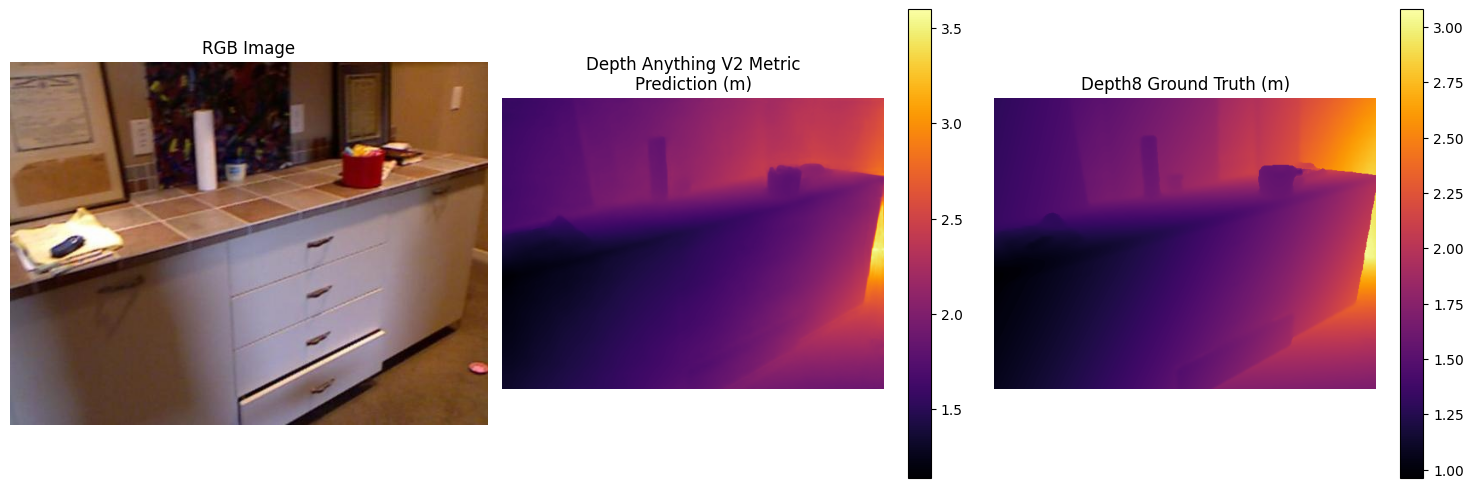

In [ ]:
# Visualize prediction vs ground truth
gt_depth = np.load(
    "/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs/depth_01.npy"
)


plt.figure(figsize=(15,5))


plt.subplot(1,3,1)
plt.imshow(img[:,:,::-1])
plt.title("RGB Image")
plt.axis("off")


plt.subplot(1,3,2)
plt.imshow(pred_metric_depth, cmap="inferno")
plt.title("Depth Anything V2 Metric\nPrediction (m)")
plt.colorbar()
plt.axis("off")


plt.subplot(1,3,3)
plt.imshow(gt_depth, cmap="inferno")
plt.title("Depth8 Ground Truth (m)")
plt.colorbar()
plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
error = pred_metric_depth - gt_depth

MAE = np.mean(np.abs(error))

RMSE = np.sqrt(np.mean(error**2))


print("MAE:", MAE)
print("RMSE:", RMSE)

MAE: 0.23035277
RMSE: 0.242216


The Depth8 ground truth may contain invalid pixels (often 0 or missing values).
MAE/RMSE only should be computed based on valid depth pixels.

In [ ]:
mask = gt_depth > 0

MAE = np.mean(
    np.abs(pred_metric_depth[mask] - gt_depth[mask])
)

RMSE = np.sqrt(
    np.mean(
        (pred_metric_depth[mask] - gt_depth[mask])**2
    )
)

print(MAE, RMSE)

0.23035277 0.242216


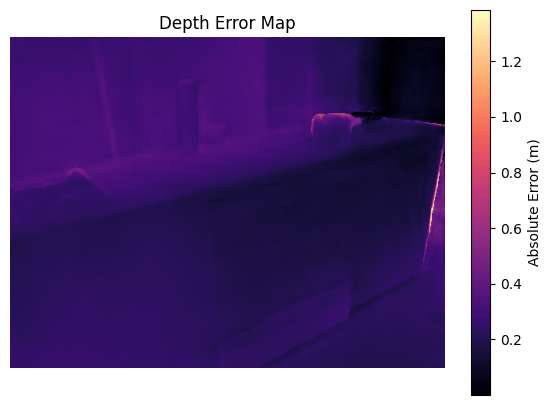

In [ ]:
# Checking the error distribution
# The error map shows where the model fails.

error_map = np.abs(pred_metric_depth - gt_depth)


plt.figure(figsize=(7,5))
plt.imshow(error_map, cmap="magma")
plt.colorbar(label="Absolute Error")
plt.title("Depth Error Map")
plt.axis("off")
plt.show()

small error → uniform regions (walls, floor)

larger error → object boundaries, reflective surfaces, thin objects

Because depth values are different at different distances, the **Absolute Relative Error (AbsRel)**  can be calculated:




$$
\mathrm{AbsRel} = \frac{1}{N}\sum_{i=1}^{N}\frac{|D_p^{(i)}-D_{gt}^{(i)}|}{D_{gt}^{(i)}}
$$

where:

- $D_p^{(i)}$ is the predicted depth value for pixel $i$
- $D_{gt}^{(i)}$ is the ground-truth depth value for pixel $i$
- $N$ is the number of valid depth pixels

In [ ]:
abs_rel = np.mean(
    np.abs(pred_metric_depth - gt_depth) / gt_depth
)

print("Abs Relative Error:", abs_rel)

Abs Relative Error: 0.1532571
